# Comparación de sistemas: Península, Baleares y Canarias

En `02_modelo.ipynb` construí el modelo paso a paso con la Península:

```
demanda_mwh ~ hdd + cdd + C(dia_semana) + festivo + C(anio)      con errores estándar HAC
```

Aquí no lo vuelvo a construir: **lo aplico a Baleares y Canarias, miro qué recoge y qué no en cada sistema, y comparo cuánto pesa la temperatura en los tres.**

1. **La demanda de cada sistema**: perfil por mes y cuánto se mueven HDD y CDD.
2. **Qué cambio del modelo para las islas**: Canarias va sin `hdd` y `maxlags` se elige en cada sistema.
3. **Cómo ajusta el modelo** en los tres sistemas a la vez.
4. **Qué falla** en cada sistema.
5. **Resultados**: los efectos con su IC 95 % HAC, cuánto pesa la temperatura en cada sistema y el modelo día a día.
6. **Conclusiones**.

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import acf

RAIZ = Path.cwd().parent          # Jupyter arranca en notebooks/, así que subo un nivel
sys.path.append(str(RAIZ / "src"))

from config import FIGURAS
from features import CONFIG
from graficos import (
    COLORES,
    NOMBRES_MES,
    NOMBRES_SISTEMA,
    plot_serie_real_prediccion,
    plot_v_sistemas,
)
from modelo import (
    ajustar_modelo,
    ajustar_sistemas,
    cargar_datos,
    formula_sistema,
    tabla_resultados,
)

FIGURAS.mkdir(parents=True, exist_ok=True)


def resumen_ajuste(res, df):
    """Lo principal de un ajuste, con los coeficientes en % de la demanda media del sistema."""
    media = df["demanda_mwh"].mean()
    coef = res.params / media * 100
    return pd.Series({
        "R²": res.rsquared,
        "SD residuo (%)": res.resid.std() / media * 100,
        "sábado (%)": coef["C(dia_semana)[T.5]"],
        "domingo (%)": coef["C(dia_semana)[T.6]"],
        "festivo (%)": coef["festivo"],
        "2025 vs 2021 (%)": coef["C(anio)[T.2025]"],
        "hdd (%)": coef.get("hdd", np.nan),
        "cdd (%)": coef["cdd"],
    })

## 1. La demanda de cada sistema

In [3]:
datos = cargar_datos()   # los tres sistemas con las variables del modelo (src/modelo.py)

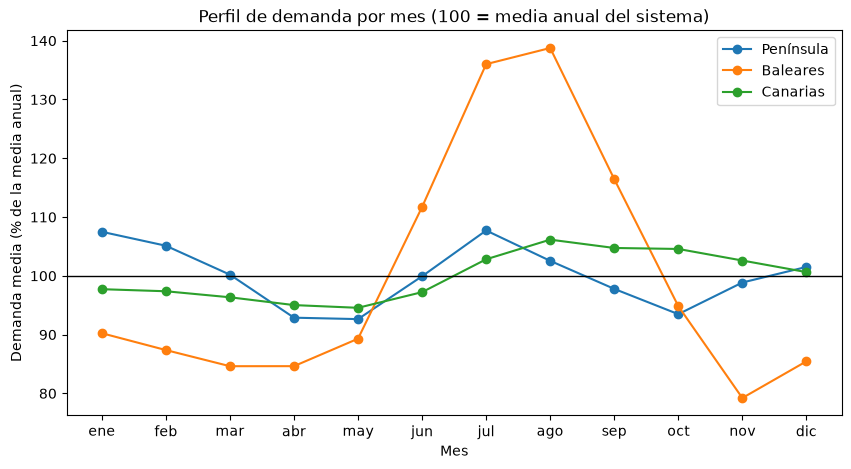

,t_base,temp mín,temp máx,días HDD > 0,HDD medio en esos días,días CDD > 0
peninsular,17.0,2.7,30.4,974.0,5.5,852.0
baleares,16.0,5.4,31.9,721.0,3.3,1105.0
canarias,16.0,13.0,30.9,42.0,0.7,1784.0


In [4]:
# perfil mensual: demanda media de cada mes en % de la media anual del sistema
fig, ax = plt.subplots(figsize=(10, 5))
for sistema, df in datos.items():
    perfil = df["demanda_mwh"].groupby(df["mes"]).mean() / df["demanda_mwh"].mean() * 100
    ax.plot(NOMBRES_MES, perfil.values, marker="o", color=COLORES[sistema], label=NOMBRES_SISTEMA[sistema])
ax.axhline(100, color="black", linewidth=1)
ax.set_title("Perfil de demanda por mes (100 = media anual del sistema)")
ax.set_xlabel("Mes")
ax.set_ylabel("Demanda media (% de la media anual)")
ax.legend()
fig.savefig(FIGURAS / "perfil_mensual.png", dpi=120, bbox_inches="tight")
plt.show()

# cuánto se mueven HDD y CDD en cada sistema
pd.DataFrame({
    sistema: {
        "t_base": CONFIG[sistema]["t_base"],
        "temp mín": df["temperatura"].min(),
        "temp máx": df["temperatura"].max(),
        "días HDD > 0": (df["hdd"] > 0).sum(),
        "HDD medio en esos días": df.loc[df["hdd"] > 0, "hdd"].mean(),
        "días CDD > 0": (df["cdd"] > 0).sum(),
    }
    for sistema, df in datos.items()
}).T.round(1)

**Qué se ve:**

- **Tres estacionalidades muy distintas.** 
    - La Península tiene dos picos parecidos, invierno (enero 107 %) y verano (julio 108 %), con los valles en primavera y otoño (93 %). 
    - Baleares tiene un solo pico enorme en verano: pasa del 79 % en noviembre al 139 % en agosto.
    - Canarias es casi plana (entre 95 % y 106 %), con algo más de demanda de agosto a noviembre.
    
- **El pico de Baleares no puede ser solo calor.** 
    - En la Península, con julio y agosto a 26 °C de media, la demanda sube entre un 3 % y un 8 % sobre la media anual. 
    - En Baleares, con 27 °C, sube un 36-39 %. Es el turismo, que llega a la vez que el calor.

- **HDD y CDD se mueven muy distinto en cada sistema.** En la Península hay frío y calor en proporciones parecidas (974 y 852 días).
    - Baleares tiene más días de calor que de frío, y sus días fríos lo son menos (3,3 grados de media frente a 5,5).
    - En Canarias casi todo es calor: 1784 días con CDD > 0 y solo 42 con HDD > 0.

## 2. Qué cambio del modelo para las islas

El modelo es el mismo que en la Península, con dos ajustes que salen de lo que acabo de ver en los datos de las islas.

### Canarias va sin `hdd`

En la tabla de arriba, Canarias tiene solo 42 días con HDD > 0 en cinco años, con 0,7 grados de media en esos días.

Para estimar una pendiente la variable tiene que moverse: si HDD es casi siempre 0, su coeficiente sale con un intervalo enorme. Lo compruebo ajustando el modelo completo, con `hdd`.

In [5]:
# Canarias CON hdd: ¿se puede estimar el efecto del frío?
df_can = datos["canarias"]
res_can = ajustar_modelo(df_can, "demanda_mwh ~ hdd + cdd + C(dia_semana) + festivo + C(anio)")

canarias_hdd = res_can.conf_int().loc[["hdd", "cdd"]] / df_can["demanda_mwh"].mean() * 100
canarias_hdd.columns = ["IC inf", "IC sup"]
canarias_hdd.insert(0, "efecto %", res_can.params[["hdd", "cdd"]] / df_can["demanda_mwh"].mean() * 100)
canarias_hdd["ancho IC"] = canarias_hdd["IC sup"] - canarias_hdd["IC inf"]
canarias_hdd.round(2)

,efecto %,IC inf,IC sup,ancho IC
hdd,2.39,-0.22,5.00,5.22
cdd,1.28,1.00,1.56,0.56


El intervalo de `hdd` va del −0,2 % al 5,0 %: unas 9 veces más ancho que el de `cdd` y ni siquiera se distingue de 0. 

Con 42 días fríos en cinco años, y con solo 0,7 grados de HDD de media en esos días, no hay variación suficiente para estimar una pendiente. Y aunque se pudiera, su peso práctico sería mínimo. Por eso en Canarias el modelo va sin `hdd`.

### `maxlags` se elige en cada sistema

En la Península (`02_modelo.ipynb`) elegí `maxlags` = 14 porque la ACF de los residuos baja de 0,1 a las dos semanas. 

En las islas no es así, y usar el mismo 14 dejaría los intervalos demasiado estrechos.

Por eso `ajustar_modelo` elige `maxlags` en cada ajuste con la misma regla: el primer retardo en el que la ACF baja de 0,1.

In [6]:
filas_acf = {}
for sistema, df in datos.items():
    res = ajustar_modelo(df, formula_sistema(sistema))
    autocorr = acf(res.resid, nlags=60)
    filas_acf[sistema] = {**{f"ACF {k} días": autocorr[k] for k in (1, 7, 14, 28, 60)},
                          "maxlags elegido": res.cov_kwds["maxlags"]}
pd.DataFrame(filas_acf).T.round(2)

,ACF 1 días,ACF 7 días,ACF 14 días,ACF 28 días,ACF 60 días,maxlags elegido
peninsular,0.72,0.35,0.08,-0.04,-0.02,14.0
baleares,0.79,0.48,0.37,0.20,-0.14,35.0
canarias,0.88,0.75,0.67,0.57,0.25,80.0


- En Baleares la ACF sigue en 0,37 a los 14 días y `maxlags` sale 35. En Canarias sigue en 0,67 a los 14 días y en 0,25 a los 60, y `maxlags` sale 80.
- Con 14 retardos, el intervalo de `cdd` habría salido entre un 25 % (Baleares) y un 37 % (Canarias) más estrecho. Las conclusiones no cambian, porque todos los efectos siguen siendo claramente distintos de 0, pero los intervalos de la tabla final ya son los correctos.
- Que en Canarias la autocorrelación dure meses indica algo lento que el modelo no recoge. Una primera idea es que Canarias solo tiene "dos estaciones".

## 3. Cómo ajusta el modelo

Ajusto el modelo en los tres sistemas, con los dos cambios de la sección 2, y lo miro de dos formas: las cifras del ajuste y la V sobre los datos.

Como los tamaños son muy distintos (la Península consume unas 27 veces más que Canarias), todo va en % de la demanda media de cada sistema.

In [7]:
modelos = ajustar_sistemas(datos)   # el modelo final de cada sistema, con errores HAC

pd.DataFrame({sistema: resumen_ajuste(res, datos[sistema]) for sistema, res in modelos.items()}).round(2)

,peninsular,baleares,canarias
R²,0.83,0.89,0.78
SD residuo (%),4.25,7.34,3.38
sábado (%),-9.44,-4.57,-4.07
domingo (%),-15.42,-8.88,-9.14
festivo (%),-18.38,-5.86,-8.46
2025 vs 2021 (%),-1.52,12.08,9.78
hdd (%),1.92,3.53,NaN
cdd (%),1.69,5.18,1.26


**Qué dicen las cifras:**

- **El calendario pesa la mitad en las islas.** El domingo baja la demanda un 15 % en la Península y un 9 % en Baleares y Canarias. Un festivo, un 18 % frente a un 6–8 %.

- **El nivel va en sentidos opuestos.** De 2021 a 2025 la demanda baja un 1,5 % en la Península y sube un 12 % en Baleares y un 10 % en Canarias.
    - `C(anio)` lo recoge en cada sistema, así que no se mezcla con la temperatura.

- **El efecto de la temperatura es muy distinto**: Baleares reacciona mucho más a la temperatura que la Península. 
    - Al frío, 3,5 % frente a 1,9 % por grado-día; al calor, 5,2 % frente a 1,7 %. 
    - Canarias es la que menos reacciona al calor (1,3 %).

- **R² y error no cuentan lo mismo.** El R² mide qué parte de la variación de la demanda explica el modelo: 
    - Baleares tiene el R² más alto (0,89) y a la vez el error más grande (7,3 %). La demanda de Baleares varía muchísimo a lo largo del año y el modelo recoge esa variación, así que su R² es alto aunque falle por bastante en días concretos.

    - Canarias tiene el R² más bajo (0,78) y el error más pequeño (3,4 %). La de Canarias apenas se mueve, y aunque el error es pequeño, pesa mucho en comparación con esa poca variación.

### La V sobre los datos

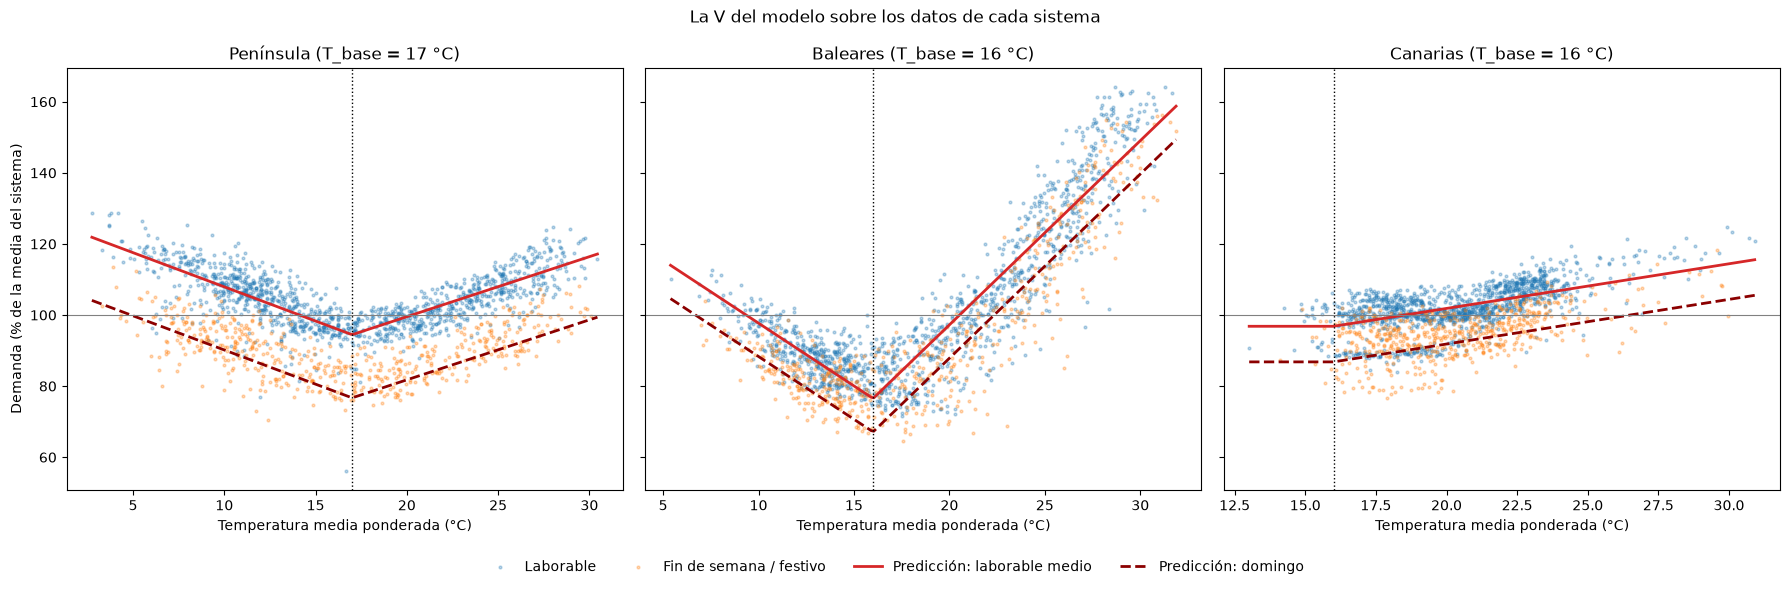

In [8]:
plot_v_sistemas(datos, modelos, {s: cfg["t_base"] for s, cfg in CONFIG.items()}, "ajuste_v_sistemas.png")

**Qué se ve:**

Con el eje en % de la media de cada sistema, las tres V se pueden comparar directamente.

- **Península**: una V casi simétrica, y la del domingo está unos 18 puntos más abajo. El modelo sigue bien las dos nubes.

- **Baleares**: la rama del calor es muy empinada. La predicción pasa del 77 % de la media a 16 °C a casi el 160 % a 32 °C. La del domingo está solo unos 9 puntos más abajo. En los días más calurosos los puntos quedan por encima de la línea: la nube se curva hacia arriba y la recta se queda corta.

- **Canarias**: la V es casi plana. Casi todos los días están entre el 90 % y el 110 % de la media, y la temperatura mueve poco la demanda. La nube es ancha para lo poco que se mueve.

## 4. Qué falla

El residuo es lo que el modelo no explica: demanda real menos predicción, en % de la demanda media de cada sistema. Lo miro por meses: **en qué época del año** se equivoca el modelo en cada sistema.

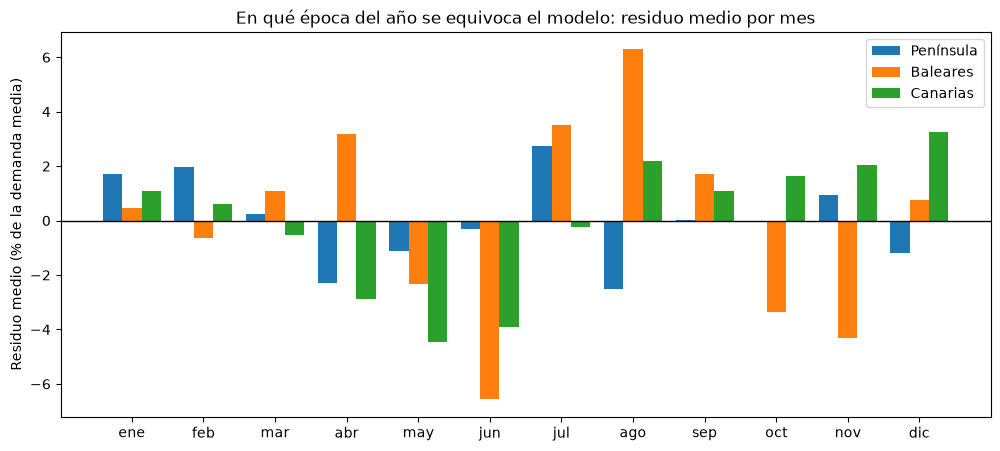

,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,dic
peninsular,1.7,2.0,0.2,-2.3,-1.1,-0.3,2.7,-2.5,0.0,-0.0,0.9,-1.2
baleares,0.5,-0.7,1.1,3.2,-2.3,-6.6,3.5,6.3,1.7,-3.4,-4.3,0.7
canarias,1.1,0.6,-0.5,-2.9,-4.5,-3.9,-0.2,2.2,1.1,1.7,2.0,3.2


In [9]:
residuos_pct = {s: res.resid / datos[s]["demanda_mwh"].mean() * 100 for s, res in modelos.items()}

por_mes = pd.DataFrame({s: r.groupby(r.index.month).mean() for s, r in residuos_pct.items()})
por_mes.index = NOMBRES_MES

fig, ax = plt.subplots(figsize=(12, 5))
ancho = 0.27
x = np.arange(12)
for k, sistema in enumerate(por_mes.columns):
    ax.bar(x + (k - 1) * ancho, por_mes[sistema], width=ancho, color=COLORES[sistema],
           label=NOMBRES_SISTEMA[sistema])
ax.axhline(0, color="black", linewidth=1)
ax.set_xticks(x, NOMBRES_MES)
ax.set_ylabel("Residuo medio (% de la demanda media)")
ax.set_title("En qué época del año se equivoca el modelo: residuo medio por mes")
ax.legend()
fig.savefig(FIGURAS / "fallos_por_mes.png", dpi=120, bbox_inches="tight")
plt.show()

por_mes.round(1).T

**Qué se ve:**

- **Baleares es donde más falla el modelo, y sigue la temporada turística.** Junio queda un 6,6 % por debajo (calor sin todos los turistas), julio y agosto un 3,5 % y un 6,3 % por encima (calor con todos los turistas), y octubre y noviembre un 3,4 % y un 4,3 % por debajo (todavía hace calor, pero ya no hay turistas). Abril queda por encima (+3,2 %), con el arranque de la temporada y la Semana Santa. El modelo aprende una sola rama del calor y la reparte entre meses con muy distinto número de turistas.

- **Canarias tiene su propio ciclo**: la primavera queda por debajo (abril a junio, entre −2,9 % y −4,5 %) y de agosto a diciembre por encima (hasta +3,2 %).

- **La Península falla menos**, y sobre todo por el calendario: julio +2,7 % y agosto −2,5 % (vacaciones), enero y febrero por encima, y abril por debajo (Semana Santa).

## 5. Resultados

El efecto de cada grado-día de frío (HDD) y de calor (CDD) sobre la demanda diaria, en % de la demanda media de cada sistema, con su intervalo de confianza al 95 % (errores HAC, con el `maxlags` de cada sistema).

In [10]:
# la misma función que usa src/modelo.py para guardar results/efectos_temperatura.csv
tabla_final = tabla_resultados(datos, modelos).rename(index=NOMBRES_SISTEMA)
tabla_final[["hdd_%", "hdd_ic_inf", "hdd_ic_sup", "cdd_%", "cdd_ic_inf", "cdd_ic_sup", "r2", "maxlags"]].round(2)

,hdd_%,hdd_ic_inf,hdd_ic_sup,cdd_%,cdd_ic_inf,cdd_ic_sup,r2,maxlags
sistema,,,,,,,,
Península,1.92,1.75,2.10,1.69,1.51,1.86,0.83,14
Baleares,3.53,3.03,4.03,5.18,4.80,5.56,0.89,35
Canarias,NaN,NaN,NaN,1.26,0.98,1.53,0.78,80


Es la misma tabla que guarda `src/modelo.py` en `results/efectos_temperatura.csv`: las dos salen de la función `tabla_resultados`. Aquí muestro solo los efectos; el CSV también incluye el peso de la temperatura (más abajo) y el Durbin-Watson. Canarias no tiene valores de `hdd` porque su modelo va sin esa variable (sección 2).

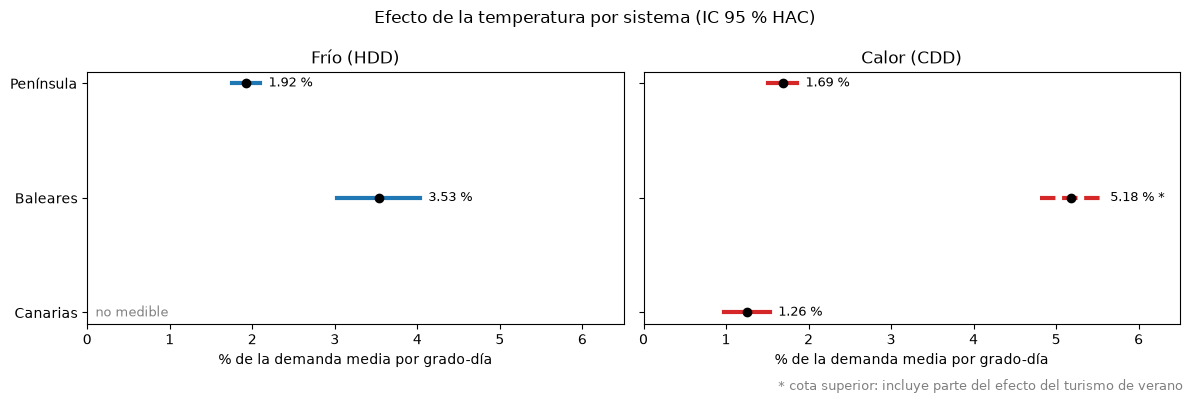

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (var, titulo, color) in zip(axes, [("hdd", "Frío (HDD)", "tab:blue"), ("cdd", "Calor (CDD)", "tab:red")]):
    for y, sistema in enumerate(tabla_final.index):
        efecto, inf, sup = tabla_final.loc[sistema, [f"{var}_%", f"{var}_ic_inf", f"{var}_ic_sup"]]
        if np.isnan(efecto):
            ax.text(0.1, y, "no medible", va="center", fontsize=9, color="gray")
            continue
        cota = sistema == NOMBRES_SISTEMA["baleares"] and var == "cdd"   # incluye turismo: cota superior
        ax.plot([inf, sup], [y, y], color=color, linewidth=3, linestyle="--" if cota else "-")
        ax.plot(efecto, y, "o", color="black", markersize=6)
        ax.text(sup + 0.1, y, f"{efecto:.2f} %" + (" *" if cota else ""), va="center", fontsize=9)
    ax.set_title(titulo)
    ax.set_xlim(0, 6.5)
    ax.set_xlabel("% de la demanda media por grado-día")
axes[0].set_yticks(range(len(tabla_final)), tabla_final.index)
axes[0].invert_yaxis()
fig.suptitle("Efecto de la temperatura por sistema (IC 95 % HAC)")
fig.text(0.99, -0.02, "* cota superior: incluye parte del efecto del turismo de verano",
         ha="right", fontsize=9, color="gray")
plt.tight_layout()
fig.savefig(FIGURAS / "efectos_sistemas.png", dpi=120, bbox_inches="tight")
plt.show()

**Qué se ve:**

- **La temperatura importa en los tres sistemas**: todos los efectos son claramente distintos de 0, incluso con los errores HAC de cada sistema.

- **Baleares es el sistema más sensible**: cada grado-día de frío sube su demanda un 3,5 %, casi el doble que en la Península (1,9 %), y cada grado-día de calor un 5,2 %, el triple (1,7 %). 
    - Los intervalos no se solapan, así que la diferencia es clara. El calor de Baleares va en discontinua porque es una cota superior: incluye parte del turismo de verano (sección 4).
    
- **Canarias es la que menos reacciona al calor** (1,3 %), y el frío no se puede medir. Como en Canarias la temperatura cambia poco a lo largo del año, la demanda reacciona poco a ella, aunque el efecto sigue siendo claramente distinto de 0.

### Cuánto pesa la temperatura

El efecto por grado-día dice **cuánto reacciona** la demanda a cada grado, pero no **cuánto importa** la temperatura en total, que depende también de cuántos grados-día tiene cada sistema.

Por eso calculo qué parte de la demanda media se debe a la temperatura: el HDD (o CDD) medio de los datos por sistema multiplicado por su efecto por grado-día.

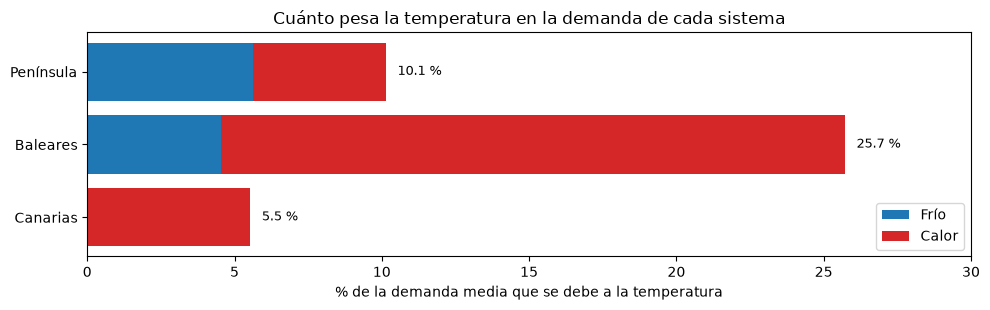

sistema,Península,Baleares,Canarias
hdd_medio_dia,2.9,1.3,0.0
cdd_medio_dia,2.7,4.1,4.4
peso_frio_%,5.6,4.5,0.0
peso_calor_%,4.5,21.2,5.5
peso_temperatura_%,10.1,25.7,5.5


In [12]:
peso = tabla_final[["hdd_medio_dia", "cdd_medio_dia", "peso_frio_%", "peso_calor_%", "peso_temperatura_%"]]

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.barh(peso.index, peso["peso_frio_%"], color="tab:blue", label="Frío")
ax.barh(peso.index, peso["peso_calor_%"], left=peso["peso_frio_%"], color="tab:red", label="Calor")
for y, total in enumerate(peso["peso_temperatura_%"]):
    ax.text(total + 0.4, y, f"{total:.1f} %", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 30)
ax.set_xlabel("% de la demanda media que se debe a la temperatura")
ax.set_title("Cuánto pesa la temperatura en la demanda de cada sistema")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(FIGURAS / "peso_temperatura.png", dpi=120, bbox_inches="tight")
plt.show()

peso.T.round(1)

**Qué se ve:**

- **Península**: la temperatura explica en torno al **10 %** de la demanda media, a partes casi iguales entre el frío (5,6 %) y el calor (4,5 %): tiene inviernos y veranos marcados.
- **Baleares**: en torno al **26 %**, y el calor solo un 21 %. Es donde más pesa la temperatura, aunque ese 21 % hereda la cota superior del efecto del calor: una parte es turismo.
- **Canarias**: en torno al **5,5 %**, todo calor. Tiene más grados-día de calor al día que la Península (4,4 frente a 2,7), pero son suaves y la demanda reacciona poco a cada uno, así que la temperatura es la que menos pesa.

### El modelo final día a día

Y la prueba más directa: la demanda real de cada día frente a la que predice el modelo, durante un año completo. En % de la demanda media de cada sistema, para poder ponerlos en la misma escala.

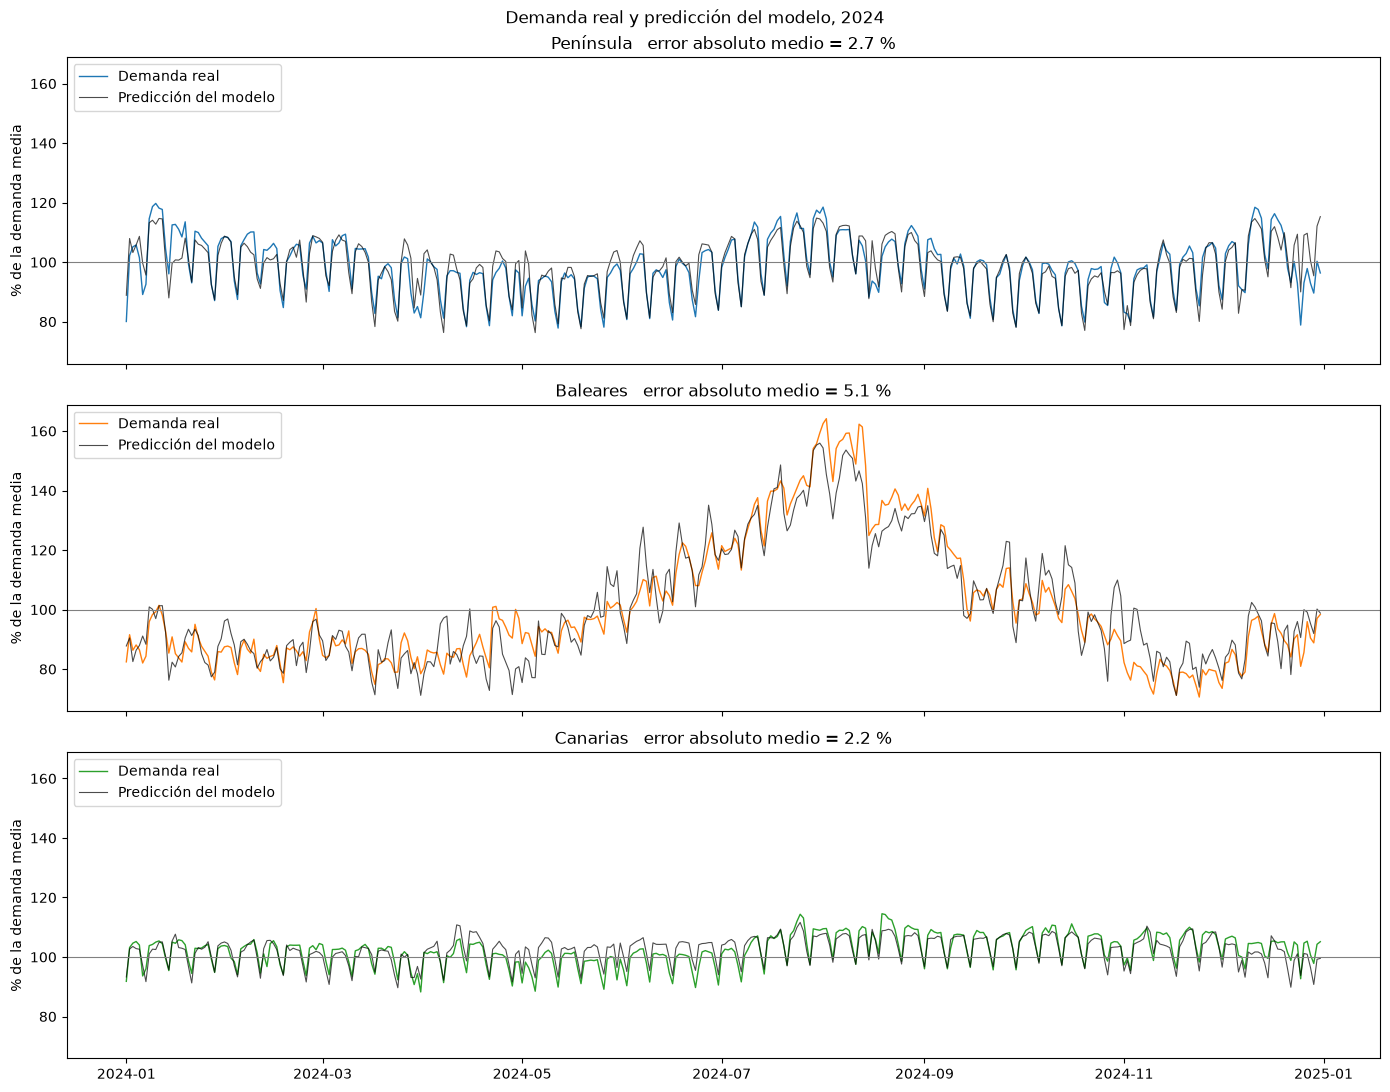

{'peninsular': fecha
 2024-01-01    -8.794973
 2024-01-02    -5.754723
 2024-01-03     1.908880
 2024-01-04    -0.005840
 2024-01-05    -7.171555
                 ...    
 2024-12-27   -11.844671
 2024-12-28    -7.562285
 2024-12-29    -5.806304
 2024-12-30   -11.805879
 2024-12-31   -18.924685
 Length: 366, dtype: float64,
 'baleares': fecha
 2024-01-01   -5.334082
 2024-01-02    1.095045
 2024-01-03    3.826949
 2024-01-04    1.768085
 2024-01-05   -1.445021
                 ...   
 2024-12-27   -3.188488
 2024-12-28   -4.879747
 2024-12-29   -3.129175
 2024-12-30   -3.163586
 2024-12-31   -0.468019
 Length: 366, dtype: float64,
 'canarias': fecha
 2024-01-01   -1.471636
 2024-01-02    0.471835
 2024-01-03    1.108802
 2024-01-04    2.386762
 2024-01-05    1.397913
                 ...   
 2024-12-27    4.376944
 2024-12-28    4.237388
 2024-12-29    7.073508
 2024-12-30    5.050169
 2024-12-31    5.606078
 Length: 366, dtype: float64}

In [14]:
ANIO_SERIE = 2024
plot_serie_real_prediccion(datos, modelos, ANIO_SERIE, "serie_real_prediccion.png")

**Qué se ve:**

- **Península** (error medio del 2,7 %): el modelo sigue muy bien la serie, con el diente de sierra semanal y los picos de invierno y verano. Falla sobre todo en Navidad y en Semana Santa.

- **Baleares** (5,1 %): acierta la forma de la temporada, pero se queda corto en el pico de agosto (principalmente por no incluir el turismo) y se pasa en octubre y noviembre, cuando aún hay días de calor pero ya no turistas. Es lo mismo que salía en el residuo por mes.

- **Canarias** (2,2 %): la demanda se mueve poco y el modelo la sigue de cerca. Queda algo por encima de la real de abril a junio y por debajo en agosto y en diciembre.

- Los errores grandes no están repartidos al azar: se concentran en épocas concretas (Navidad, temporada turística). Es lo que el modelo no tiene: nuevas variables de turismo y de días festivos o puentes que añadan esta información al modelo.

## 6. Conclusiones

### Resultado: efecto por grado-día (IC 95 % HAC) y peso de la temperatura, en % de la demanda media

| Sistema | Frío (HDD) | Calor (CDD) | Peso de la temperatura |
|---|---|---|---|
| Península | 1,92 % (1,75 – 2,10) | 1,69 % (1,51 – 1,86) | 10 % |
| Baleares | 3,53 % (3,03 – 4,03) | 5,18 % (4,80 – 5,56)\* | 26 % |
| Canarias | no medible | 1,26 % (0,98 – 1,53) | 5,5 % |

\* Cota superior: incluye parte del efecto del turismo de verano.

### Qué me dice
- **La temperatura importa en los tres sistemas**: todos los efectos son claramente significativos, incluso con los errores HAC de cada sistema.
- **Baleares es el sistema más sensible**: casi el doble que la Península con el frío y el triple con el calor, aunque esta última cifra está inflada por el turismo. Es también donde la temperatura pesa más: una cuarta parte de su demanda.
- **La Península** reacciona algo más al frío que al calor, y la temperatura explica en torno al 10 % de su demanda.
- **Canarias** es donde la temperatura pesa menos (5,5 %) y el frío no se puede medir. 
- **Por qué podría salir así** (hipótesis: no tengo el reparto de la demanda por sectores): 
    - En la Península hay mucha demanda industrial que no depende de la temperatura (el domingo la demanda baja un 15 %, frente a un 9 % en las islas).
    - En las islas pesa más el consumo de hogares, hoteles y comercios, que es el que enciende la climatización.
    - Canarias tiene un clima tan estable que la temperatura casi nunca se aleja del confort.
- **El modelo de la Península funciona en las islas**, con dos ajustes (sin `hdd` en Canarias y `maxlags` por sistema), pero falla donde el turismo marca la demanda: en Baleares, sobre todo en junio, agosto y el otoño.

### Limitaciones propias de las islas
- **Turismo sin controlar**: en Baleares infla el efecto del calor y en Canarias deja una estacionalidad que el modelo no explica. Haría falta una serie de turistas.
- **Pocos puntos de temperatura**: en Canarias solo hay dos (Las Palmas y Santa Cruz) para siete islas, y en Baleares tres.
- **Sin datos por sectores**: la explicación de por qué los sistemas reaccionan distinto es una hipótesis.

Las limitaciones comunes a los tres sistemas están en `02_modelo.ipynb`.